# Laboratorio 10 - Deep Learning

- Juan Diego Solís Martínez - 23720
- Victor Manuel Pérez Chávez - 23731
- Diego Oswaldo Flores Rivas - 23714

## Task 4

In [11]:
import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import spearmanr
from torchvision import models, transforms

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 160)
print("Semilla aleatoria:", SEED)

Semilla aleatoria: 42


Se reconstruyen el modelo, las imágenes y el Grad-CAM del Task 1.2 con el mismo código y semilla. La función de Grad-CAM recibe ahora el modelo como argumento, para poder aplicarla también a los modelos aleatorizados del Task 4.2; el gradiente $\partial y^c/\partial A$ se captura con un hook sobre el tensor de salida de `layer4`, que es equivalente al hook de retroceso del Task 1.2.

In [12]:
pesos = models.ResNet18_Weights.IMAGENET1K_V1
modelo = models.resnet18(weights=pesos).eval()
clases = pesos.meta["categories"]

MEDIA, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
recorte = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
normalizar = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEDIA, STD)])

rutas = {"a": "images/a_objeto.jpg", "b": "images/b_dos_objetos.jpg", "c": "images/c_fuera_contexto.jpg"}
imgs = {k: recorte(Image.open(r).convert("RGB")) for k, r in rutas.items()}   # imágenes 224 x 224
x = {k: normalizar(im).unsqueeze(0) for k, im in imgs.items()}

def gradcam(m, xin, c):
    guardado = {}
    def hook(mod, inp, out):                      # A: (1, 512, 7, 7) y su gradiente dy^c/dA
        guardado["A"] = out
        out.register_hook(lambda g: guardado.__setitem__("dA", g))
    h = m.layer4.register_forward_hook(hook)
    m.zero_grad()
    logits = m(xin)
    logits[0, c].backward()                       # desde el logit y^c, antes del softmax
    h.remove()
    A, dA = guardado["A"][0].detach(), guardado["dA"][0].detach()
    alpha = dA.mean(dim=(1, 2))                   # alpha_k^c = (1/Z) sum_ij dy^c/dA_ij^k
    L_crudo = (alpha[:, None, None] * A).sum(0)   # sum_k alpha_k^c A^k (7 x 7, sin ReLU)
    L7 = F.relu(L_crudo)                          # L^c = ReLU(sum_k alpha_k^c A^k) en 7 x 7
    L = F.interpolate(L7[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    L = (L - L.min()) / (L.max() - L.min())       # normalización mínimo-máximo
    return {"L": L.numpy(), "L7": L7, "L_crudo": L_crudo, "alpha": alpha, "A": A,
            "prob": F.softmax(logits.detach(), 1)[0]}

top1, gc = {}, {}
for k in rutas:
    with torch.no_grad():
        top1[k] = modelo(x[k]).argmax(1).item()
    gc[k] = gradcam(modelo, x[k], top1[k])
    print(f"Imagen ({k}): clase {top1[k]} {clases[top1[k]]:22s} p = {gc[k]['prob'][top1[k]]:.4f}")

Imagen (a): clase 281 tabby                  p = 0.3879
Imagen (b): clase 208 Labrador retriever     p = 0.3702
Imagen (c): clase 171 Italian greyhound      p = 0.1692


### Task 4.1

Deletion e insertion con $P = 20$ pasos sobre la clase de mayor probabilidad. En el paso $k$ se modifican los $\lfloor k \cdot 224^2 / P \rceil$ píxeles más importantes según el mapa de Grad-CAM de 224 × 224 del Task 1.2 (los tres canales de cada píxel a la vez).

- **Deletion:** los píxeles elegidos pasan a gris medio (0.5 en cada canal antes de normalizar, como en el Task 1.4 c).
- **Insertion:** se parte de la imagen con desenfoque gaussiano ($\sigma = 10$ píxeles, núcleo de 61) y los píxeles elegidos toman su valor original.

En ambos casos $\text{AUC} = \frac{1}{P}\sum_{k=1}^{P} c_k$. Los empates del mapa (los píxeles donde la ReLU deja el mapa en cero) se ordenan por posición. La línea base son 10 permutaciones aleatorias de los píxeles, las mismas para las tres imágenes y para ambas métricas.

In [13]:
P, N_ORD = 20, 10
NPIX = 224 * 224
a_tensor = transforms.ToTensor()
pix = {k: a_tensor(im) for k, im in imgs.items()}                                 # (3, 224, 224) en [0, 1]
gris = {k: torch.full_like(p, 0.5) for k, p in pix.items()}                       # gris medio
borrosa = {k: TF.gaussian_blur(p, kernel_size=61, sigma=10.0) for k, p in pix.items()}
norm_lote = transforms.Normalize(MEDIA, STD)

def curva(orden, inicio, fin, c):
    # c_0, ..., c_P: en el paso k los primeros round(k NPIX / P) píxeles de `orden` toman su valor en `fin`
    lote = []
    for k in range(P + 1):
        mascara = torch.zeros(NPIX)
        mascara[torch.as_tensor(orden[:round(k * NPIX / P)], dtype=torch.long)] = 1
        mascara = mascara.view(1, 224, 224)
        lote.append(inicio * (1 - mascara) + fin * mascara)
    with torch.no_grad():
        return F.softmax(modelo(norm_lote(torch.stack(lote))), 1)[:, c].double().numpy()

auc = lambda curv: curv[..., 1:].mean(-1)   # AUC = (1/P) sum_{k=1}^P c_k

rng = np.random.default_rng(SEED)
ordenes_azar = [rng.permutation(NPIX) for _ in range(N_ORD)]
orden_mapa = {k: np.argsort(-gc[k]["L"].ravel(), kind="stable") for k in rutas}   # de mayor a menor

t0 = time.perf_counter()
res = {}
for k in rutas:
    c = top1[k]
    res[k] = {
        "del_mapa": curva(orden_mapa[k], pix[k], gris[k], c),
        "ins_mapa": curva(orden_mapa[k], borrosa[k], pix[k], c),
        "del_azar": np.stack([curva(o, pix[k], gris[k], c) for o in ordenes_azar]),
        "ins_azar": np.stack([curva(o, borrosa[k], pix[k], c) for o in ordenes_azar]),
    }
print(f"Curvas calculadas en {time.perf_counter() - t0:.1f} s")

Curvas calculadas en 37.2 s


In [14]:
tablas_41 = {}
for k in rutas:
    filas = []
    for met, signo in [("del", -1), ("ins", +1)]:     # deletion: menor es mejor; insertion: mayor es mejor
        a_mapa = auc(res[k][f"{met}_mapa"])
        a_azar = auc(res[k][f"{met}_azar"])               # 10 AUC, una por orden aleatorio
        media, de = a_azar.mean(), a_azar.std(ddof=1)
        filas.append([a_mapa, media, de, a_mapa - media, signo * (a_mapa - media) / de])
    tablas_41[k] = pd.DataFrame(filas, index=["AUC_del", "AUC_ins"],
                                columns=["Grad-CAM", "Azar (media)", "Azar (desv. est.)", "Diferencia (mapa - azar)",
                                         "Mejora en desv. est."])
    print(f"Imagen ({k}) - clase {clases[top1[k]]}, p original = {gc[k]['prob'][top1[k]]:.4f}")
    print(tablas_41[k].round(4).to_string(), "\n")
print("Mejora en desv. est.: (azar - mapa)/s en deletion y (mapa - azar)/s en insertion; positivo = mejor que el azar.")

Imagen (a) - clase tabby, p original = 0.3879
         Grad-CAM  Azar (media)  Azar (desv. est.)  Diferencia (mapa - azar)  Mejora en desv. est.
AUC_del    0.0651        0.1026             0.0185                   -0.0375                2.0236
AUC_ins    0.3702        0.1350             0.0097                    0.2352               24.2634 

Imagen (b) - clase Labrador retriever, p original = 0.3702
         Grad-CAM  Azar (media)  Azar (desv. est.)  Diferencia (mapa - azar)  Mejora en desv. est.
AUC_del    0.0189        0.0124             0.0039                    0.0065               -1.6733
AUC_ins    0.7273        0.2110             0.0290                    0.5164               17.7768 

Imagen (c) - clase Italian greyhound, p original = 0.1692
         Grad-CAM  Azar (media)  Azar (desv. est.)  Diferencia (mapa - azar)  Mejora en desv. est.
AUC_del    0.0003        0.0087             0.0057                   -0.0084                1.4696
AUC_ins    0.0833        0.0144          

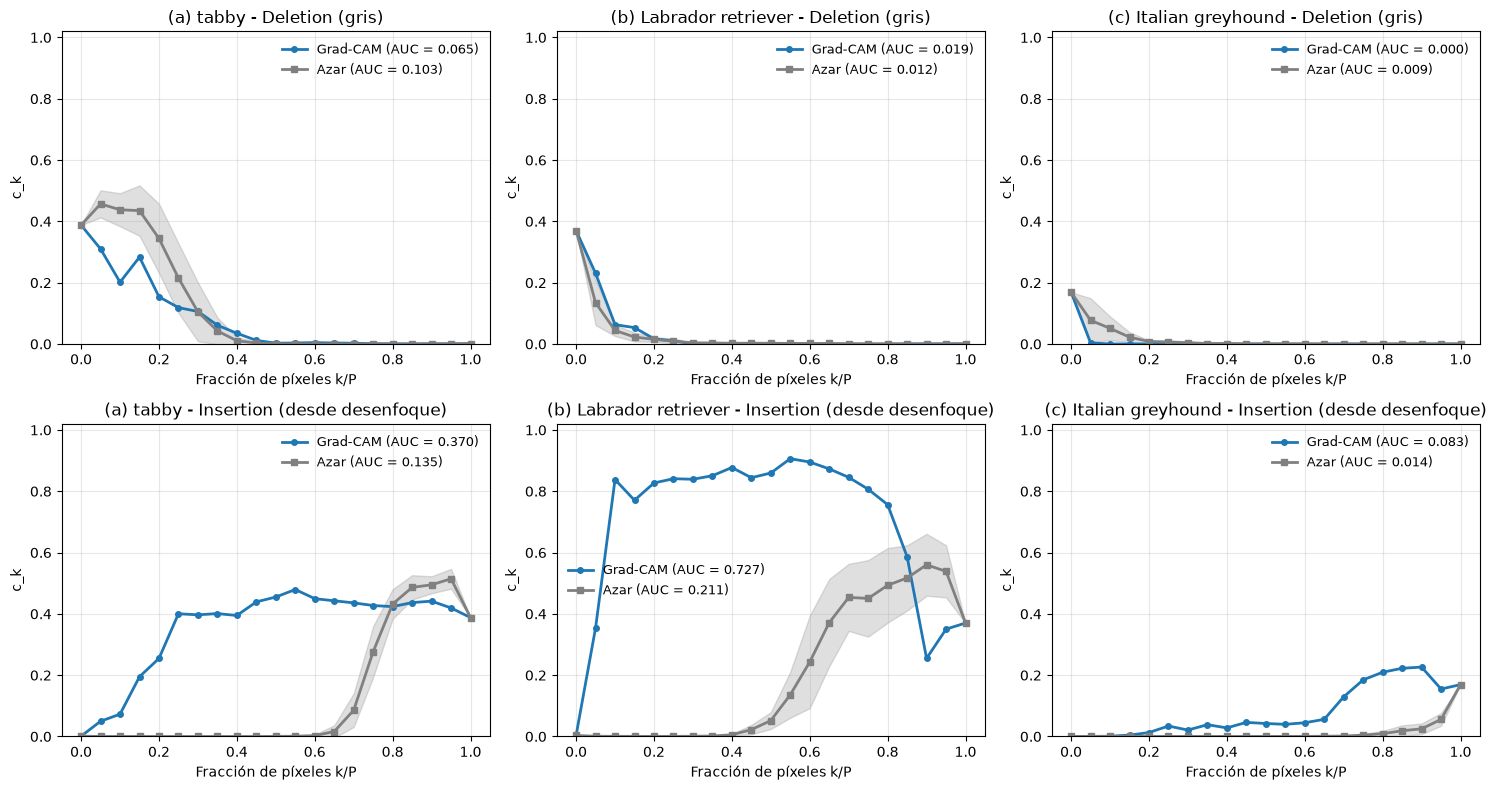

In [15]:
fracs = np.arange(P + 1) / P
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, k in enumerate(rutas):
    for i, (met, nombre) in enumerate([("del", "Deletion (gris)"), ("ins", "Insertion (desde desenfoque)")]):
        a, az = ax[i, j], res[k][f"{met}_azar"]
        a.plot(fracs, res[k][f"{met}_mapa"], "o-", lw=2, ms=4, label=f"Grad-CAM (AUC = {auc(res[k][f'{met}_mapa']):.3f})")
        a.plot(fracs, az.mean(0), "s-", lw=2, ms=4, color="gray", label=f"Azar (AUC = {auc(az).mean():.3f})")
        a.fill_between(fracs, az.mean(0) - az.std(0, ddof=1), az.mean(0) + az.std(0, ddof=1), color="gray", alpha=0.25)
        a.set_title(f"({k}) {clases[top1[k]]} - {nombre}"); a.set_xlabel("Fracción de píxeles k/P"); a.set_ylabel("c_k")
        a.set_ylim(0, 1.02); a.grid(alpha=0.3); a.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

### Task 4.2

Prueba de aleatorización de parámetros en cascada. Sobre una copia del modelo se reinicializan de forma acumulada `fc`, `layer4`, `layer3`, `layer2`, `layer1` y `conv1`, llamando a `reset_parameters()` de cada submódulo (la inicialización por defecto de PyTorch: Kaiming uniforme en convoluciones y capas lineales; en BatchNorm, pesos 1, sesgos 0 y estadísticas de ejecución en media 0 y varianza 1). En la etapa `conv1` también se reinicializa `bn1`, que es la normalización que le sigue. En cada etapa se calcula el mapa de Grad-CAM de 7 × 7 (con ReLU, sin interpolar) para la clase top-1 del modelo original y su Spearman con el mapa original. Como referencia también se reporta el Spearman del mapa sin ReLU.

In [16]:
def reinicializar(m, nombre):
    for modulo in ([m.conv1, m.bn1] if nombre == "conv1" else [getattr(m, nombre)]):
        for sub in modulo.modules():
            if hasattr(sub, "reset_parameters"):
                sub.reset_parameters()

def spearman_7x7(a, b):
    a, b = a.numpy().ravel(), b.numpy().ravel()
    if a.std() == 0 or b.std() == 0:              # mapa constante (por ejemplo, todo cero tras la ReLU)
        return np.nan
    return spearmanr(a, b)[0]

etapas = ["fc", "layer4", "layer3", "layer2", "layer1", "conv1"]
torch.manual_seed(SEED)
modelo_rand = copy.deepcopy(modelo)
cascada = {}                                      # cascada[etapa][imagen] = resultado de gradcam
filas_rho, filas_crudo, filas_pred = [], [], []
for e in etapas:
    reinicializar(modelo_rand, e)
    cascada[e] = {k: gradcam(modelo_rand, x[k], top1[k]) for k in rutas}
    filas_rho.append([spearman_7x7(cascada[e][k]["L7"], gc[k]["L7"]) for k in rutas])
    filas_crudo.append([spearman_7x7(cascada[e][k]["L_crudo"], gc[k]["L_crudo"]) for k in rutas])
    filas_pred.append([f"{clases[cascada[e][k]['prob'].argmax()]} / {cascada[e][k]['prob'][top1[k]]:.4f}" for k in rutas])

indice = pd.Index([f"{i + 1}. hasta {e}" for i, e in enumerate(etapas)], name="Etapa")
cols_img = [f"({k}) {clases[top1[k]]}" for k in rutas]
tabla_rho = pd.DataFrame(filas_rho, index=indice, columns=cols_img)
tabla_crudo = pd.DataFrame(filas_crudo, index=indice, columns=cols_img)
print("Spearman entre el mapa Grad-CAM 7x7 (con ReLU) aleatorizado y el original:")
print(tabla_rho.round(4).to_string())
print("\nSpearman del mapa 7x7 sin ReLU:")
print(tabla_crudo.round(4).to_string())
print("\nNueva predicción top-1 / probabilidad de la clase original:")
print(pd.DataFrame(filas_pred, index=indice, columns=cols_img).to_string())

Spearman entre el mapa Grad-CAM 7x7 (con ReLU) aleatorizado y el original:
                 (a) tabby  (b) Labrador retriever  (c) Italian greyhound
Etapa                                                                    
1. hasta fc        -0.5392                  0.1545                 0.5440
2. hasta layer4     0.1574                 -0.2086                -0.2491
3. hasta layer3     0.0678                  0.0754                    NaN
4. hasta layer2    -0.2780                  0.0948                    NaN
5. hasta layer1     0.4119                  0.2738                    NaN
6. hasta conv1      0.3213                  0.1922                    NaN

Spearman del mapa 7x7 sin ReLU:
                 (a) tabby  (b) Labrador retriever  (c) Italian greyhound
Etapa                                                                    
1. hasta fc        -0.5670                  0.1029                 0.5001
2. hasta layer4     0.1357                 -0.2221                -0.0621
3. h

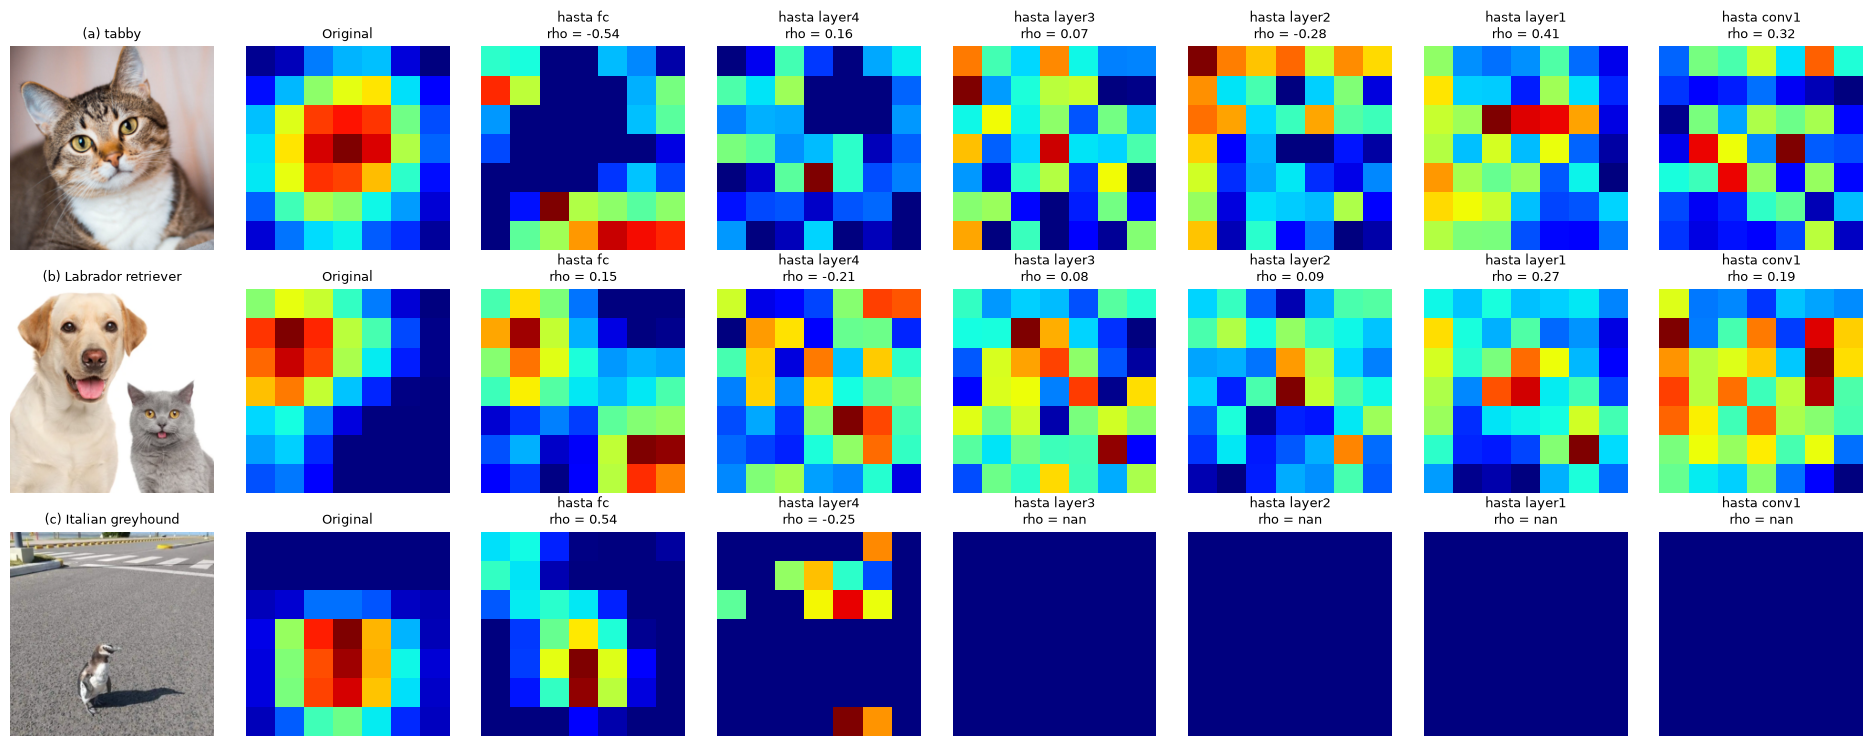

In [17]:
def ver(a, L7, titulo):
    a.imshow(L7.numpy(), cmap="jet"); a.set_title(titulo, fontsize=9); a.axis("off")

fig, ax = plt.subplots(3, 8, figsize=(19, 7.5))
for i, k in enumerate(rutas):
    ax[i, 0].imshow(imgs[k]); ax[i, 0].set_title(f"({k}) {clases[top1[k]]}", fontsize=9); ax[i, 0].axis("off")
    ver(ax[i, 1], gc[k]["L7"], "Original")
    for j, e in enumerate(etapas):
        ver(ax[i, j + 2], cascada[e][k]["L7"], f"hasta {e}\nrho = {tabla_rho.iloc[j, i]:.2f}")
plt.tight_layout(); plt.show()

### Task 4.3

**a.** Resumen de las desviaciones estándar, estructura del mapa (cuántas de las 49 celdas son positivas y cuánta área queda en el empate en cero) y curvas paso a paso.

In [18]:
resumen = pd.DataFrame({f"({k})": tablas_41[k]["Mejora en desv. est."] for k in rutas}).T
print("Mejora sobre el azar, en desviaciones estándar de la distribución aleatoria:")
print(resumen.round(2).to_string())

print("\nEstructura del mapa:")
filas = []
for k in rutas:
    L7, L = gc[k]["L7"].numpy(), gc[k]["L"]
    filas.append([(L7 > 0).sum(), (L7 > 0).sum() / 49, (L > 0).mean(), (L7.max() - np.sort(L7.ravel())[-2]) / L7.max()])
print(pd.DataFrame(filas, index=[f"({k})" for k in rutas],
                   columns=["Celdas 7x7 > 0", "Fracción de celdas > 0", "Fracción de píxeles L > 0",
                            "Brecha entre 1.ª y 2.ª celda (rel.)"]).round(4).to_string())
print("Cada celda de 7x7 equivale a 32 x 32 = 1024 píxeles (2.04 % de la imagen); cada paso k/P cubre el 5 %, unas 2.45 celdas.")

for k in rutas:
    tab = pd.DataFrame({"k/P": fracs,
                        "del mapa": res[k]["del_mapa"], "del azar": res[k]["del_azar"].mean(0),
                        "ins mapa": res[k]["ins_mapa"], "ins azar": res[k]["ins_azar"].mean(0)})
    print(f"\nCurvas de ({k}):")
    print(tab.round(4).to_string(index=False))

Mejora sobre el azar, en desviaciones estándar de la distribución aleatoria:
     AUC_del  AUC_ins
(a)     2.02    24.26
(b)    -1.67    17.78
(c)     1.47    23.78

Estructura del mapa:
     Celdas 7x7 > 0  Fracción de celdas > 0  Fracción de píxeles L > 0  Brecha entre 1.ª y 2.ª celda (rel.)
(a)              49                  1.0000                     0.9949                               0.0712
(b)              36                  0.7347                     0.8265                               0.0652
(c)              35                  0.7143                     0.7857                               0.0310
Cada celda de 7x7 equivale a 32 x 32 = 1024 píxeles (2.04 % de la imagen); cada paso k/P cubre el 5 %, unas 2.45 celdas.

Curvas de (a):
 k/P  del mapa  del azar  ins mapa  ins azar
0.00    0.3879    0.3879    0.0011    0.0011
0.05    0.3102    0.4570    0.0497    0.0001
0.10    0.2016    0.4379    0.0728    0.0001
0.15    0.2835    0.4352    0.1951    0.0001
0.20    0.1540    0

Deletion en la imagen (a) con la referencia desenfocada en lugar del gris (mismos órdenes del mapa y del azar).

Deletion en (a) tabby:
             AUC_del mapa  AUC_del azar (media)  Azar (desv. est.)  Mejora en desv. est.  c_P (imagen 100 % referencia)
Gris               0.0651                0.1026             0.0185                2.0236                         0.0010
Desenfocada        0.0548                0.1226             0.0110                6.1326                         0.0011
Imagen de referencia gris: p(tabby) = 0.0010, top-1 = letter opener (0.0406)
Imagen de referencia desenfocada: p(tabby) = 0.0011, top-1 = Windsor tie (0.0497)


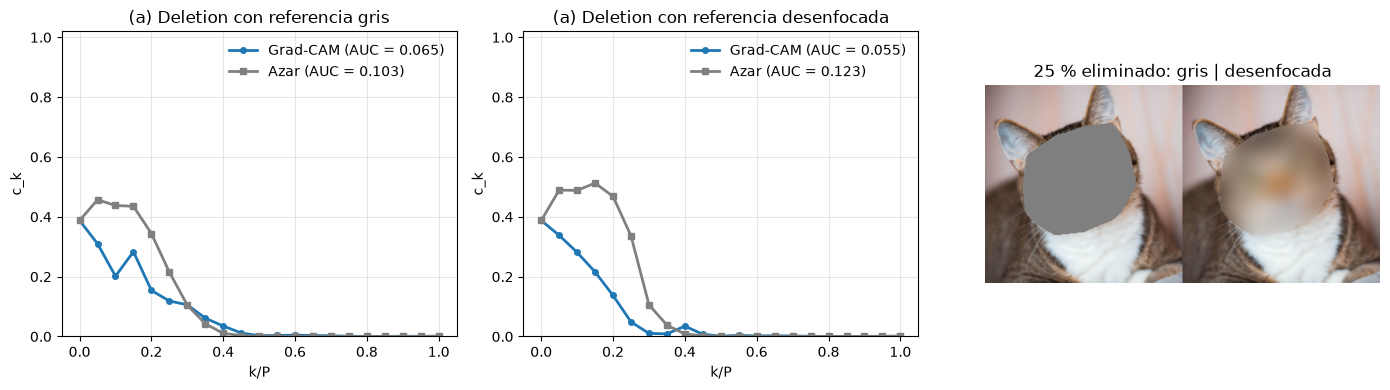

In [19]:
k = "a"; c = top1[k]
del_borr_mapa = curva(orden_mapa[k], pix[k], borrosa[k], c)
del_borr_azar = np.stack([curva(o, pix[k], borrosa[k], c) for o in ordenes_azar])

filas = []
for ref, cm, ca in [("Gris", res[k]["del_mapa"], res[k]["del_azar"]), ("Desenfocada", del_borr_mapa, del_borr_azar)]:
    am, aa = auc(cm), auc(ca)
    filas.append([am, aa.mean(), aa.std(ddof=1), (aa.mean() - am) / aa.std(ddof=1), ca[:, -1].mean()])
print(f"Deletion en ({k}) {clases[c]}:")
print(pd.DataFrame(filas, index=["Gris", "Desenfocada"],
                   columns=["AUC_del mapa", "AUC_del azar (media)", "Azar (desv. est.)", "Mejora en desv. est.",
                            "c_P (imagen 100 % referencia)"]).round(4).to_string())

with torch.no_grad():
    p_ref = {n: F.softmax(modelo(norm_lote(r[None])), 1)[0] for n, r in [("gris", gris[k]), ("desenfocada", borrosa[k])]}
for n, p in p_ref.items():
    print(f"Imagen de referencia {n}: p({clases[c]}) = {p[c]:.4f}, top-1 = {clases[p.argmax()]} ({p.max():.4f})")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (n, cm, ca) in zip(ax[:2], [("gris", res[k]["del_mapa"], res[k]["del_azar"]), ("desenfocada", del_borr_mapa, del_borr_azar)]):
    a.plot(fracs, cm, "o-", lw=2, ms=4, label=f"Grad-CAM (AUC = {auc(cm):.3f})")
    a.plot(fracs, ca.mean(0), "s-", lw=2, ms=4, color="gray", label=f"Azar (AUC = {auc(ca).mean():.3f})")
    a.set_title(f"({k}) Deletion con referencia {n}"); a.set_xlabel("k/P"); a.set_ylabel("c_k"); a.set_ylim(0, 1.02)
    a.grid(alpha=0.3); a.legend(frameon=False)
# Imagen al 25 % de deletion con cada referencia
m25 = torch.zeros(NPIX); m25[torch.as_tensor(orden_mapa[k][:NPIX // 4], dtype=torch.long)] = 1; m25 = m25.view(1, 224, 224)
ax[2].imshow(torch.cat([pix[k] * (1 - m25) + gris[k] * m25, pix[k] * (1 - m25) + borrosa[k] * m25], 2).permute(1, 2, 0))
ax[2].set_title("25 % eliminado: gris | desenfocada"); ax[2].axis("off")
plt.tight_layout(); plt.show()

**b.** Primera etapa en que el Spearman baja de 0.3 en cada imagen. Para la etapa `fc` se verifica la predicción teórica: las activaciones $A$ no cambian, $\alpha_k^c = w_k^{c,\text{nuevo}}/Z$, y el mapa es una combinación lineal aleatoria de los mismos 512 canales. Se estima además la distribución del Spearman esperado repitiendo solo la reinicialización de `fc` 200 veces (sin retropropagar: el mapa es $\sum_k (w_k^{c,\text{nuevo}}/Z) A^k$).

In [20]:
for k, col in zip(rutas, cols_img):
    bajo = tabla_rho[col] < 0.3
    print(f"({k}) primera etapa con Spearman < 0.3: {bajo.idxmax() if bajo.any() else 'ninguna'}")

print("\nVerificación en la etapa fc:")
torch.manual_seed(SEED)
m_fc = copy.deepcopy(modelo); reinicializar(m_fc, "fc")
Wn = m_fc.fc.weight.detach()
for k in rutas:
    r = gradcam(m_fc, x[k], top1[k])
    print(f"   ({k}) max|A_nuevo - A_orig| = {(r['A'] - gc[k]['A']).abs().max():.2e}   "
          f"max|alpha - w_nuevo/Z| = {(r['alpha'] - Wn[top1[k]] / 49).abs().max():.2e}   "
          f"cos(w_nuevo, w_orig) = {F.cosine_similarity(Wn[top1[k]], modelo.fc.weight[top1[k]].detach(), 0):+.4f}")

# Distribución del Spearman con 200 reinicializaciones de fc
capa = torch.nn.Linear(512, 1000)
filas = []
for k in rutas:
    rhos = []
    for s in range(200):
        torch.manual_seed(1000 + s); capa.reset_parameters()
        L7 = F.relu(torch.einsum("k,kij->ij", capa.weight.detach()[top1[k]] / 49, gc[k]["A"]))
        rhos.append(spearman_7x7(L7, gc[k]["L7"]))
    rhos = np.array(rhos)
    filas.append([np.nanmean(rhos), np.nanstd(rhos), np.nanpercentile(rhos, 5), np.nanpercentile(rhos, 95),
                  np.mean(rhos[~np.isnan(rhos)] < 0.3), np.isnan(rhos).mean(), tabla_rho.iloc[0][f"({k}) {clases[top1[k]]}"]])
print("\nSpearman con fc reinicializado (200 repeticiones) frente al de la etapa 1:")
print(pd.DataFrame(filas, index=[f"({k})" for k in rutas],
                   columns=["Media", "Desv. est.", "P5", "P95", "Fracción < 0.3", "Fracción mapa nulo", "Etapa 1 (Task 4.2)"]).round(4).to_string())

# Correlación espacial entre canales: qué tan parecido es cualquier canal al mapa medio de activación
for k in rutas:
    A = gc[k]["A"].reshape(512, -1)
    media_A = A.mean(0)
    rho_media = spearmanr(media_A.numpy(), gc[k]["L7"].numpy().ravel())[0]
    print(f"({k}) Spearman entre el promedio de los 512 canales y el mapa original: {rho_media:.4f}")

(a) primera etapa con Spearman < 0.3: 1. hasta fc
(b) primera etapa con Spearman < 0.3: 1. hasta fc
(c) primera etapa con Spearman < 0.3: 2. hasta layer4

Verificación en la etapa fc:
   (a) max|A_nuevo - A_orig| = 0.00e+00   max|alpha - w_nuevo/Z| = 1.75e-10   cos(w_nuevo, w_orig) = -0.0635
   (b) max|A_nuevo - A_orig| = 0.00e+00   max|alpha - w_nuevo/Z| = 1.75e-10   cos(w_nuevo, w_orig) = +0.0189
   (c) max|A_nuevo - A_orig| = 0.00e+00   max|alpha - w_nuevo/Z| = 1.75e-10   cos(w_nuevo, w_orig) = -0.0501

Spearman con fc reinicializado (200 repeticiones) frente al de la etapa 1:
      Media  Desv. est.      P5     P95  Fracción < 0.3  Fracción mapa nulo  Etapa 1 (Task 4.2)
(a)  0.1767      0.4188 -0.4927  0.8185          0.5979               0.055             -0.5392
(b) -0.0632      0.4693 -0.7692  0.7538          0.7423               0.030              0.1545
(c)  0.0945      0.5716 -0.7917  0.9080          0.5729               0.040              0.5440
(a) Spearman entre el promedi

**c.** Error máximo de eficiencia de TreeSHAP $9.72 \times 10^{-8}$, valor base igual al promedio del fondo (diferencia 0), error de $2.43 \times 10^{-8}$ contra el Shapley exacto, MAE de 0.0025 a 0.0044 contra KernelSHAP, Spearman 0.650 entre $I_j$ y la importancia por permutación (`age`: 6.ª contra 20.ª), suma de efectos en probabilidad −0.946 contra −0.755 en el cliente rechazado, Jaccard de LIME de 0.82 con $N = 500$ y 0.911 con $N = 1\,500$, $R^2_w$ de 0.22 a 0.37, y validez de los contrafactuales del Task 3.4 de 0.87 % (174 de 20 000), con un contrafactual que pasa de $p = 0.052$ a 0.596 cambiando `checking_status` y `credit_amount` de 433 a 454.